In [40]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import seaborn as sns

In [2]:
path = "/mnt/d/Projects/perfume-market-analysis/data/processed/egypt/egypt_fragrance_merged.csv"
df = pd.read_csv(path)

In [3]:
df.columns.to_list()

['product_name',
 'inspired_by',
 'size_unit',
 'variant_type',
 'price',
 'available',
 'identity',
 'product_url',
 'collected_date',
 'size',
 'price_per_unit',
 'review_count',
 'rate',
 'inspired_by_key',
 'Perfume',
 'Brand',
 'Top',
 'Middle',
 'Base',
 'Perfumer1',
 'mainaccord1',
 'mainaccord2',
 'mainaccord3',
 'matched_type',
 'local_brand']

## Market Overview
> How Many Products and Brands Are Represented?

### The Top 20 Most Frequent Fragrance in Egypt Market

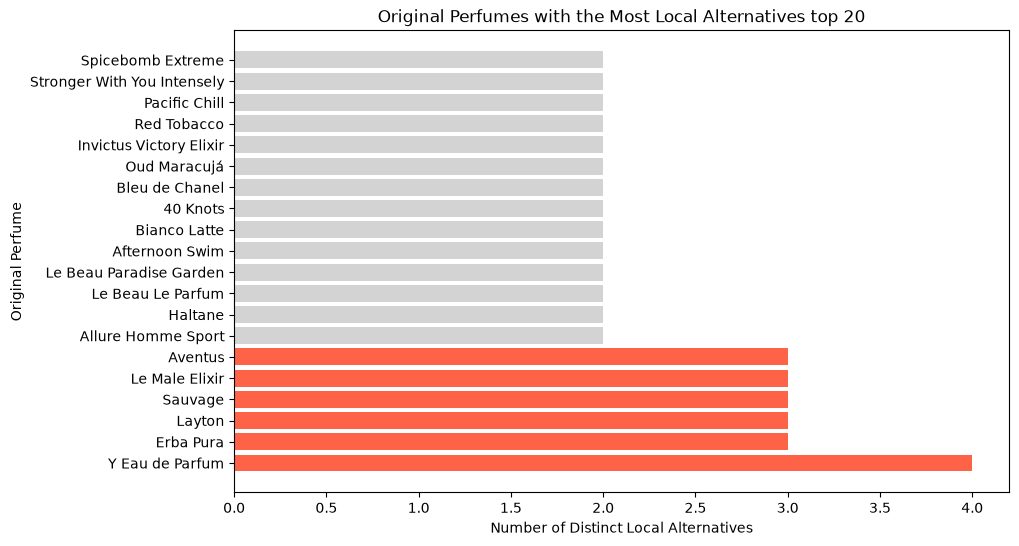

In [93]:
products_count = df.drop_duplicates(['inspired_by','local_brand']).groupby(by=['inspired_by'], as_index=False).size().sort_values(by='size', ascending=False).to_numpy()
count = 20
values = products_count[:, 1]
bar_colors = ['tomato' if v >= 3 else 'lightgray' for v in values]
plt.figure(figsize=(count * 0.5, count * 0.3))
plt.barh(products_count[:count, 0], products_count[:count, 1], align='center', color = bar_colors)
plt.title(f"Original Perfumes with the Most Local Alternatives top {count}")
plt.xlabel("Number of Distinct Local Alternatives")
plt.ylabel("Original Perfume")

plt.show()

### The Top 20 Most Frequent Brand in Egypt Market

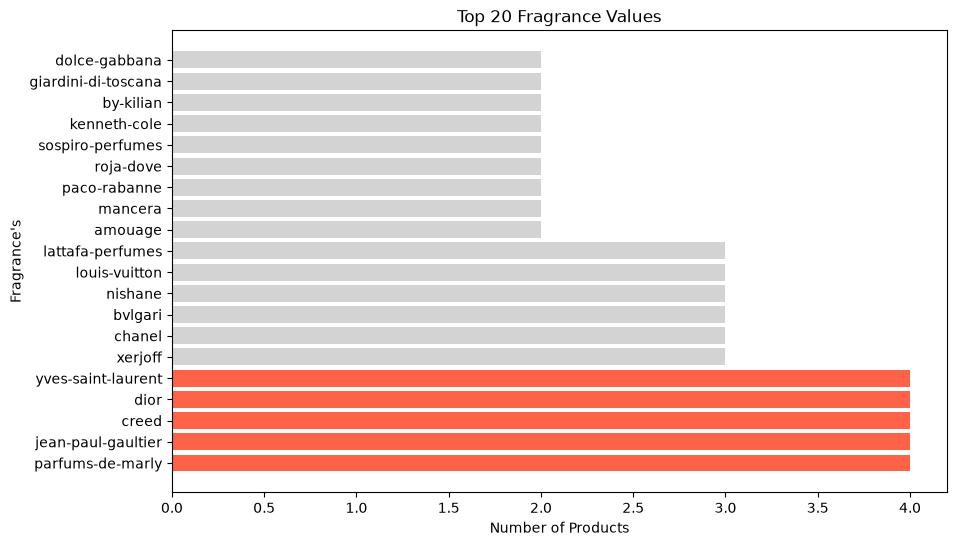

In [131]:
products_count = df.drop_duplicates(['Brand','local_brand']).groupby(by=['Brand'], as_index=False).size().sort_values(by='size', ascending=False).to_numpy()
count = 20
values = products_count[:, 1]
bar_colors = ['tomato' if v >= 4 else 'lightgray' for v in values]
plt.figure(figsize=(count * 0.5, count * 0.3))
plt.barh(products_count[:count, 0], products_count[:count, 1], align='center', color = bar_colors)
plt.title(f"Top {count} Fragrance Values")
plt.xlabel("Number of Products")
plt.ylabel("Fragrance's")
plt.show()

### from this 2 bar charts you get that :
        1- "Y eau de parfum" in all brands in egypt
        2- (y, dior, creed, jpg, pdm's) all this brands are the most used in the market        


## Brand Competition
> Which Local Brands Have The Most Products?

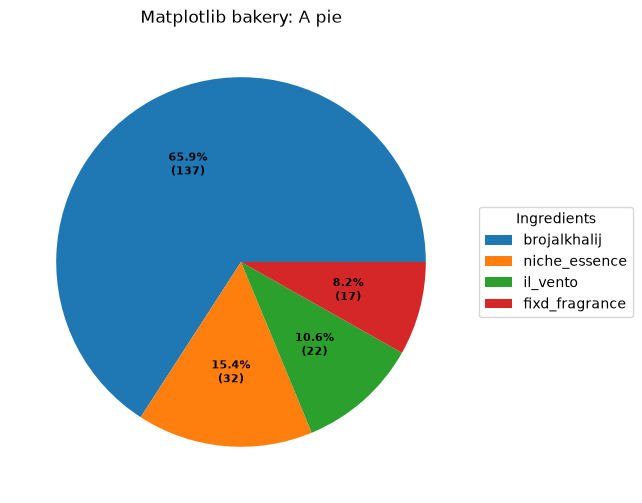

In [211]:
products_in_brand = df.drop_duplicates(['inspired_by']).groupby(by=['local_brand'], as_index=False).size().sort_values(by='size', ascending=False).to_numpy()
x = products_in_brand[:, 0]
y = products_in_brand[:, 1].astype(int)

fig, ax = plt.subplots(figsize=(12, 6))

pie = ax.pie(y)

ax.pie_label(pie, '{frac:.1%}\n({absval:d})',
             textprops=dict(color="black", size=8, weight="bold"))

ax.legend(pie.wedges, x,
          title="Ingredients",
          loc="center left",
          bbox_to_anchor=(1, 0, 0.5, 1))

ax.set_title("Matplotlib bakery: A pie")

plt.show()

## Pricing
> What are the typical prices and price ranges?</br>

(1134, 2)


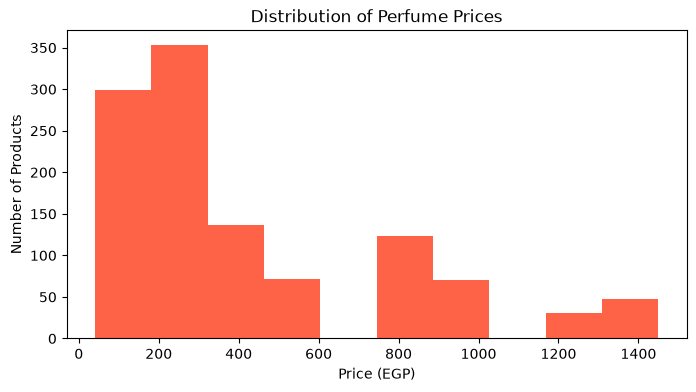

In [19]:
product_size_price = df[['price', 'size']].to_numpy()
plt.figure(figsize=(8,4))
plt.hist(product_size_price[:,0], color = 'tomato')
plt.title("Distribution of Perfume Prices")
plt.xlabel("Price (EGP)")
plt.ylabel("Number of Products")
plt.show()

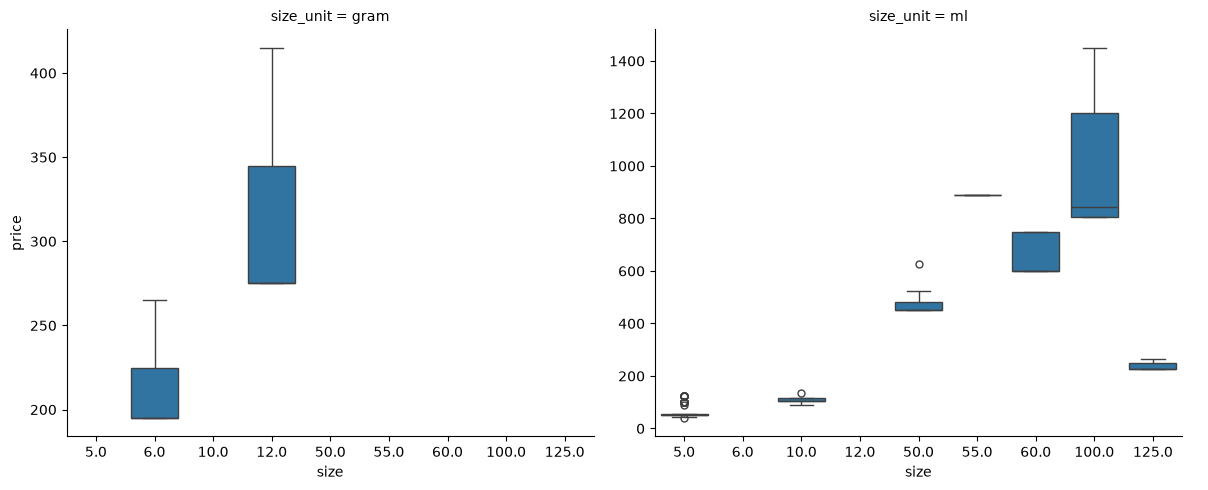

In [ ]:
product_size_price = df[['price', 'size', 'size_unit']]

# Separate box plots for each product type
sns.catplot(
    data=product_size_price,
    x="size",
    y="price",
    col="size_unit",
    kind="box",
    sharey=False,
    height=5,
    aspect=1.2
)
plt.show()

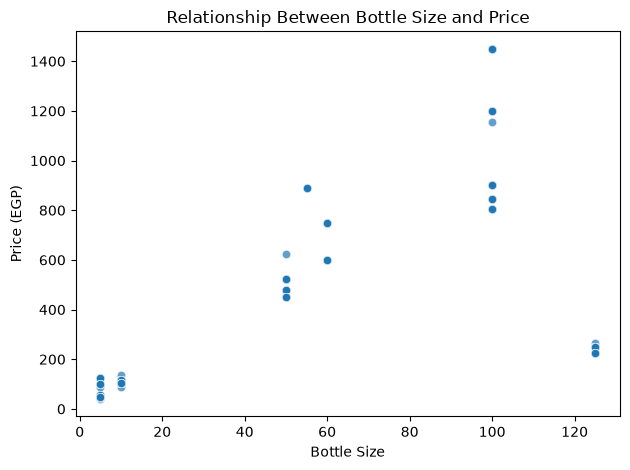

In [58]:
sns.scatterplot(
    data=product_size_price[product_size_price['size_unit'] == 'ml'],
    x="size",
    y="price",
    alpha=0.7)
plt.title("Relationship Between Bottle Size and Price")
plt.xlabel("Bottle Size")
plt.ylabel("Price (EGP)")
plt.tight_layout()
plt.show()

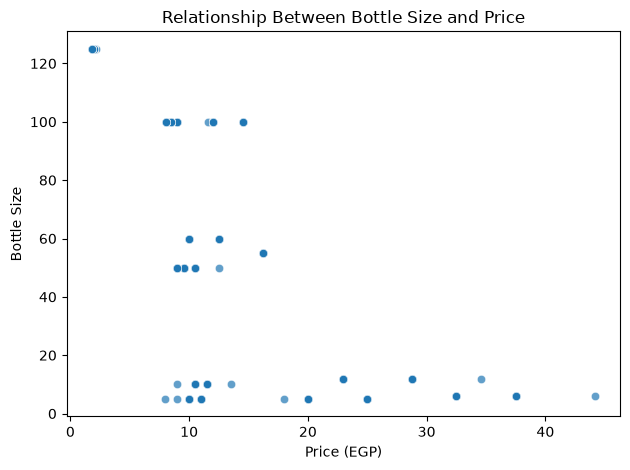

In [64]:
sns.scatterplot(
    data=df,
    x="price_per_unit",
    y="size",
    alpha=0.7)
plt.title("Relationship Between Bottle Size and Price")
plt.xlabel("Price (EGP)")
plt.ylabel("Bottle Size")
plt.tight_layout()
plt.show()

#### for competition, i will make some highlite for the local brand

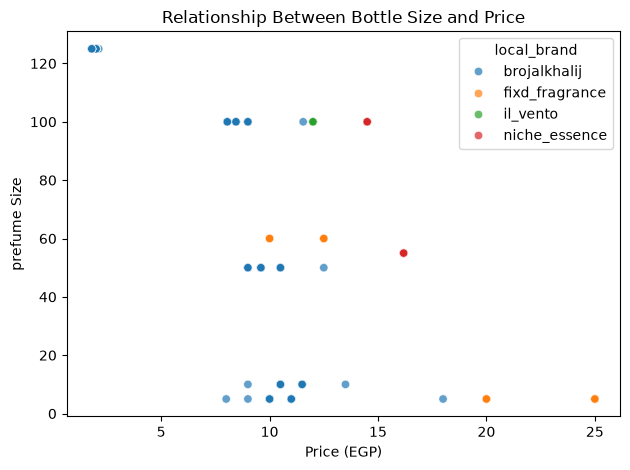

In [71]:
sns.scatterplot(
    data=df[df['size_unit'] == 'ml'],
    x="price_per_unit",
    y="size",
    hue= 'local_brand',
    alpha=0.7)
plt.title("Relationship Between Bottle Size and Price")
plt.xlabel("Price (EGP)")
plt.ylabel("prefume Size")
plt.tight_layout()
plt.show()

In [72]:
df["price"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90]
)

count    1134.000000
mean      414.285714
std       366.191452
min        40.000000
25%       115.000000
50%       250.000000
75%       600.000000
90%       890.000000
max      1450.000000
Name: price, dtype: float64

></br>
> A very useful summary for the entire things in price from unit of the size and the size varient's 
></br>
></br>

In [76]:
summary = (
    df.groupby(["variant_type", "size", "size_unit"])["price"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        minimum="min",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        maximum="max"
    )
    .round(2)
    .reset_index()
)

summary

,variant_type,size,size_unit,count,mean,median,minimum,q1,q3,maximum
0,perfume,5.0,ml,161,60.43,50.0,40.0,50.0,55.0,125.0
1,perfume,10.0,ml,138,109.24,105.0,90.0,105.0,115.0,135.0
2,perfume,50.0,ml,138,471.38,450.0,450.0,450.0,480.0,625.0
3,perfume,55.0,ml,47,890.00,890.0,890.0,890.0,890.0,890.0
4,perfume,60.0,ml,23,658.70,600.0,600.0,600.0,750.0,750.0
5,perfume,100.0,ml,216,1020.25,845.0,805.0,805.0,1200.0,1450.0
6,perfume,125.0,ml,137,235.69,225.0,225.0,225.0,250.0,265.0
7,tola,6.0,gram,137,207.99,195.0,195.0,195.0,225.0,265.0
8,tola,12.0,gram,137,305.15,275.0,275.0,275.0,345.0,415.0


### Original perfume coverage	
>Which originals have the most local alternatives?</br>


In [88]:
df["inspired_by"] = (
    df["inspired_by"]
    .astype("string")
    .str.strip()
)

df["Brand"] = df["Brand"].astype("string").str.strip()
df["product_name"] = df["product_name"].astype("string").str.strip()

# Remove rows without an identified original perfume
coverage_df = df.dropna(subset=["inspired_by"]).copy()
coverage_df = coverage_df[
    coverage_df["inspired_by"].ne("")
]

# Count distinct local products, not duplicate size variants
coverage_df = coverage_df.drop_duplicates(
    subset=["inspired_by", "Brand", "product_name"]
)

# Summarize original perfume coverage
coverage = (
    coverage_df.groupby("inspired_by")
    .agg(
        local_alternatives=("product_name", "count"),
        local_brands=("Brand", "nunique")
    )
    .sort_values(
        ["local_alternatives", "local_brands"],
        ascending=False
    )
    .reset_index()
)

coverage.head(20)

,inspired_by,local_alternatives,local_brands
0,Y Eau de Parfum,4,1
1,Aventus,3,1
2,Erba Pura,3,1
3,Layton,3,1
4,Le Male Elixir,3,1
5,Sauvage,3,1
6,Accento,2,2
7,Scandal Pour Homme,2,2
8,Allure Homme Sport,2,1
9,Bianco Latte,2,1


### Fragrance characteristics
>Which fragrance families and notes occur most often?

In [107]:
df["mainaccord1"] = (
    df["mainaccord1"]
    .astype("string")
    .str.strip()
)

df["Brand"] = df["Brand"].astype("string").str.strip()
df["product_name"] = df["product_name"].astype("string").str.strip()

# Remove rows without an identified original perfume
coverage_df = df.dropna(subset=["mainaccord1"]).copy()
coverage_df = coverage_df[
    coverage_df["mainaccord1"].ne("")
]

# Count distinct local products, not duplicate size variants
coverage_df = coverage_df.drop_duplicates(
    subset=["mainaccord1", "Brand", "product_name"]
)

# Summarize original perfume coverage
coverage = (
    coverage_df.groupby("mainaccord1")
    .agg(
        local_alternatives=("product_name", "count"),
        local_brands=("Brand", "nunique")
    )
    .sort_values(
        ["local_alternatives", "local_brands"],
        ascending=False
    )
    .reset_index()
)

coverage.head(20)

,mainaccord1,local_alternatives,local_brands
0,aromatic,30,16
1,citrus,30,15
2,warm spicy,25,15
3,woody,23,18
4,vanilla,15,9
5,fruity,11,5
6,sweet,8,6
7,amber,5,4
8,fresh spicy,5,3
9,leather,4,3
